# Rezultate — baseline vs DistilBERT vs BERT-base

Citeste metricile din `results/*_metrics.json` (produse de `src.qa.baseline`, `src.qa.train` / `src.qa.reader`) si face tabelele si figurile de comparatie. Figurile se salveaza in `docs/figures/`.

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Baseline (TF-IDF + NER)": "results/baseline_metrics.json",
    "DistilBERT": "results/reader_distilbert-base-uncased-squad_metrics.json",
    "BERT-base": "results/reader_bert-base-uncased-squad_metrics.json",
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK = "#0b0b0b"
INK_MUTED = "#52514e"
SURFACE = "#fcfcfb"
GRID = "#e5e4df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 10,
    "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})

metrics = {name: json.loads(Path(path).read_text(encoding="utf-8")) for name, path in MODELS.items()}

## 1. Rezultate globale (SQuAD v1.1 validation, 10.570 intrebari)

In [2]:
overall = pd.DataFrame({
    name: {"EM": m["exact_match"], "F1": m["f1"]} for name, m in metrics.items()
}).T
overall

,EM,F1
Baseline (TF-IDF + NER),18.98,24.68
DistilBERT,77.61,85.55
BERT-base,81.22,88.54


## 2. Pe tip de intrebare

In [3]:
qtypes = [q for q, g in metrics["BERT-base"]["by_question_type"].items() if g["count"] >= 100]


def table_by(key, metric):
    return pd.DataFrame({
        name: {k: m[key][k][metric] for k in m[key]} for name, m in metrics.items()
    })


em_by_type = table_by("by_question_type", "exact_match").loc[qtypes]
f1_by_type = table_by("by_question_type", "f1").loc[qtypes]
counts = pd.Series({q: metrics["BERT-base"]["by_question_type"][q]["count"] for q in qtypes}, name="n")
pd.concat([counts, f1_by_type.add_suffix(" F1")], axis=1).round(1)

,n,Baseline (TF-IDF + NER) F1,DistilBERT F1,BERT-base F1
what,6022,16.1,85.1,88.1
who,1108,41.6,89.2,91.5
when,713,60.1,91.0,94.2
which,699,18.6,86.9,87.7
how many,638,49.2,89.4,92.5
where,477,29.4,83.5,86.1
how,433,8.8,75.2,82.7
why,155,10.1,72.8,76.0
how much,154,41.4,87.5,90.4


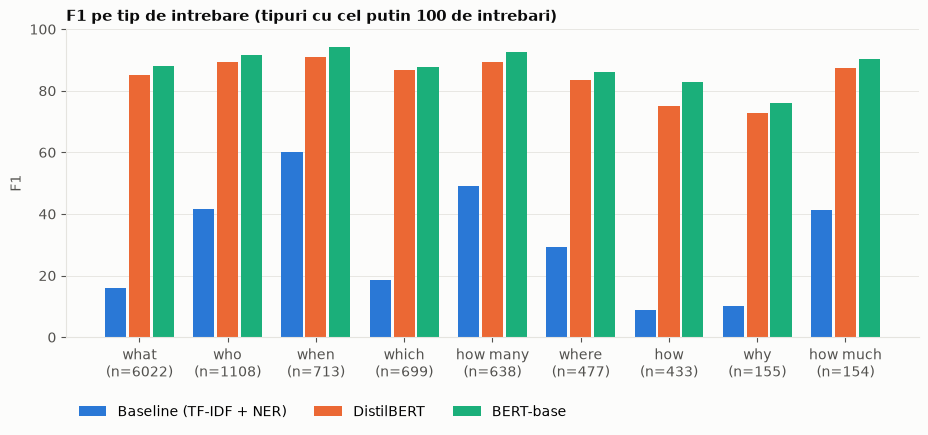

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(qtypes))
width = 0.27
for i, (name, color) in enumerate(zip(MODELS, COLORS)):
    ax.bar(x + (i - 1) * width, f1_by_type[name], width - 0.03, color=color, label=name)
ax.set_xticks(x, [f"{q}\n(n={counts[q]})" for q in qtypes])
ax.set_ylabel("F1")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.set_title("F1 pe tip de intrebare (tipuri cu cel putin 100 de intrebari)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=3)
fig.savefig(FIG_DIR / "results_f1_by_question_type.png")
plt.show()

## 3. Pe lungimea pasajului (cuvinte)

In [5]:
length_order = ["<100", "100-149", "150-199", ">=200"]
f1_by_length = table_by("by_context_length", "f1").loc[length_order]
f1_by_length.round(1)

,Baseline (TF-IDF + NER),DistilBERT,BERT-base
<100,25.1,85.3,88.0
100-149,24.6,85.8,89.2
150-199,24.4,85.1,88.6
>=200,23.3,86.1,87.7


## 4. Observatii

- BERT-base > DistilBERT > baseline pe toate tipurile de intrebari. Diferenta BERT-base vs DistilBERT e de ~3-4 puncte EM/F1, la un model de ~2x mai mic si ~2x mai rapid.
- Cel mai mare castig fata de baseline e pe "what" / "which" / "how" / "why", unde baseline-ul nu are o entitate de cautat; pe "when" si "how many" baseline-ul era deja decent datorita regulilor NER.
- "why" si "how" raman cele mai grele si pentru BERT (raspunsuri lungi, explicative, cu granite ambigue): EM ~50-68, dar F1 mult mai mare (72-83), deci modelul gaseste zona corecta dar nu exact span-ul de referinta.
- Lungimea pasajului aproape nu conteaza pentru reader (variatie < 1,5 puncte F1), ceea ce confirma ca sliding window-ul nu pierde informatie.